# Практическая работа 1B

Фильтрация изображений с использованием свёртки в Python

## Задание 1

Применить ко всем растрам из папки «Изображения» фильтры высоких и низких частот. Сохранить обработанные изображения.

In [1]:
from pathlib import Path
import tempfile
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from IPython import get_ipython
from matplotlib_inline.backend_inline import set_matplotlib_formats

get_ipython().run_line_magic('matplotlib', 'inline')
set_matplotlib_formats('jpeg', pil_kwargs={'quality': 82})
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
cv2.setNumThreads(2)

workdir = tempfile.TemporaryDirectory()
LAB = Path(workdir.name)
OUT = LAB / 'results'
OUT.mkdir()
EXAMPLES = LAB / 'images' / 'examples'
EXAMPLES.mkdir(parents=True)
cv2.imwrite(str(EXAMPLES / 'coffee.jpg'), cv2.cvtColor(data.coffee(), cv2.COLOR_RGB2BGR),
            [cv2.IMWRITE_JPEG_QUALITY, 94])
cv2.imwrite(str(EXAMPLES / 'chelsea.jpg'), cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR),
            [cv2.IMWRITE_JPEG_QUALITY, 94])
cv2.imwrite(str(EXAMPLES / 'page.png'), data.page());

In [2]:
def read_image(path, flags=cv2.IMREAD_COLOR):
    image = cv2.imread(str(path), flags)
    if image is None:
        raise FileNotFoundError(f'Не удалось прочитать {path}')
    return image


def rgb_for_plot(image):
    if image.ndim == 2:
        return image
    conversion = cv2.COLOR_BGRA2RGBA if image.shape[2] == 4 else cv2.COLOR_BGR2RGB
    return cv2.cvtColor(image, conversion)


def show_images(items, filename=None, cols=2):
    rows = (len(items) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.5 * rows), squeeze=False)
    for ax, (title, image) in zip(axes.flat, items):
        h, w = image.shape[:2]
        scale = min(1, 650 / max(h, w))
        small = cv2.resize(image, (max(1, round(w * scale)), max(1, round(h * scale))),
                           interpolation=cv2.INTER_AREA)
        ax.imshow(rgb_for_plot(small), cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')
    for ax in list(axes.flat)[len(items):]:
        ax.axis('off')
    fig.tight_layout()
    if filename:
        fig.savefig(OUT / filename, dpi=120, bbox_inches='tight', pil_kwargs={'quality': 88})
    plt.show()
    plt.close(fig)


def save_image(name, image):
    if not cv2.imwrite(str(OUT / name), image):
        raise OSError(f'Не удалось сохранить {name}')

In [3]:
from io import BytesIO
from urllib.parse import quote
from urllib.request import urlopen
from zipfile import ZipFile

TEACHER = LAB / 'teacher'
TEACHER.mkdir()
folder = '1. Фильтрация изображений с использованием свертки в Python'
url = ('https://raw.githubusercontent.com/Alexandre77777/image_processing/main/'
       + quote(folder + '/Изображения.zip', safe='/'))
with urlopen(url, timeout=60) as response:
    archive_data = response.read()
with ZipFile(BytesIO(archive_data)) as archive:
    for item in archive.infolist():
        name = Path(item.filename).name
        if Path(name).suffix.lower() in ('.jpg', '.jpeg', '.png'):
            (TEACHER / name).write_bytes(archive.read(item))

image_paths = sorted(TEACHER.iterdir())
if len(image_paths) != 5:
    raise ValueError('В архиве должны быть пять изображений')

In [4]:
mean_kernel = np.ones((5, 5), dtype=np.float32) / 25
laplace_kernel = np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]], dtype=np.float32)
sharp_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
horizontal_kernel = np.array([[-1, -1], [2, 2], [-1, -1]], dtype=np.float32)
diagonal_kernel = np.array([[-2, -1, 0], [-1, 0, 1], [0, 1, 2]], dtype=np.float32) / 4

filters = {
    'mean5': ('Среднее 5×5', mean_kernel, 'clip', 1.0),
    'laplace': ('Высокие частоты: |Лапласиан|', laplace_kernel, 'abs', 1.0),
    'sharpen': ('Повышение резкости', sharp_kernel, 'clip', 1.0),
    'horizontal': ('Горизонтальные линии', horizontal_kernel, 'abs', 1.0),
    'diagonal': ('Диагональное ядро, модуль ×2', diagonal_kernel, 'abs', 2.0),
}

def apply_filter(image, kernel, mode='clip', gain=1.0):
    response = cv2.filter2D(image, cv2.CV_32F, kernel, borderType=cv2.BORDER_REFLECT_101)
    if mode == 'abs':
        return cv2.convertScaleAbs(response, alpha=gain)
    return np.clip(np.round(response * gain), 0, 255).astype(np.uint8)

## Задание 2

Сравнить полученные изображения с исходными и составить описание (до-после). Указать, какие классы объектов стали наиболее ярко выражены. Сделать общий вывод о том, для каких целей лучше всего использовать фильтры высоких и низких частот.

### Изображение 1

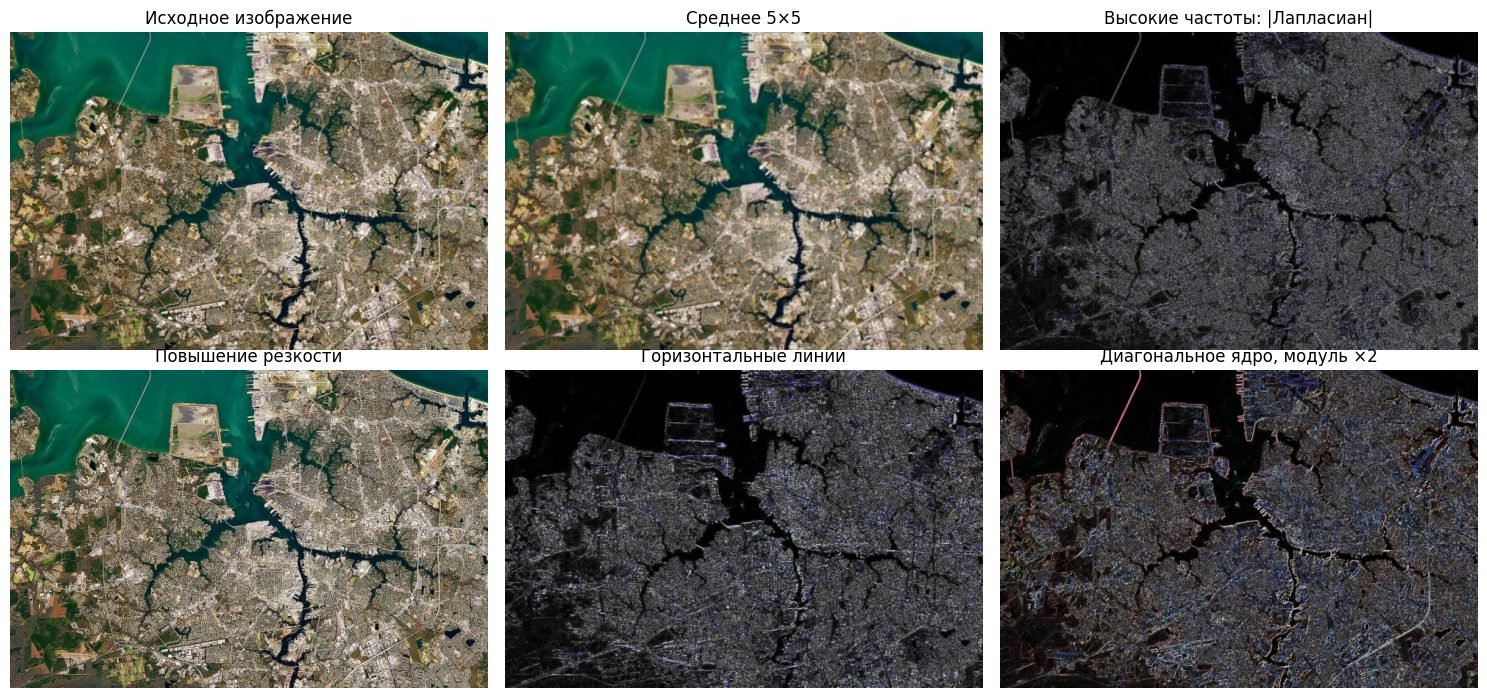

In [5]:
image = read_image(TEACHER / '1.JPG')
panels = [('Исходное изображение', image)]
for key, (title, kernel, mode, gain) in filters.items():
    filtered = apply_filter(image, kernel, mode, gain)
    target = OUT / f'01_{key}.jpg'
    if not cv2.imwrite(str(target), filtered, [cv2.IMWRITE_JPEG_QUALITY, 75]):
        raise OSError(f'Не удалось сохранить {target.name}')
    panels.append((title, filtered))
show_images(panels, '01_comparison.jpg', cols=3)
del panels, filtered, image

Усреднение сгладило мелкую застройку. На Лапласиане лучше видны береговая линия, дороги и границы кварталов. Повышение резкости подчёркивает городскую фактуру.

### Изображение 2

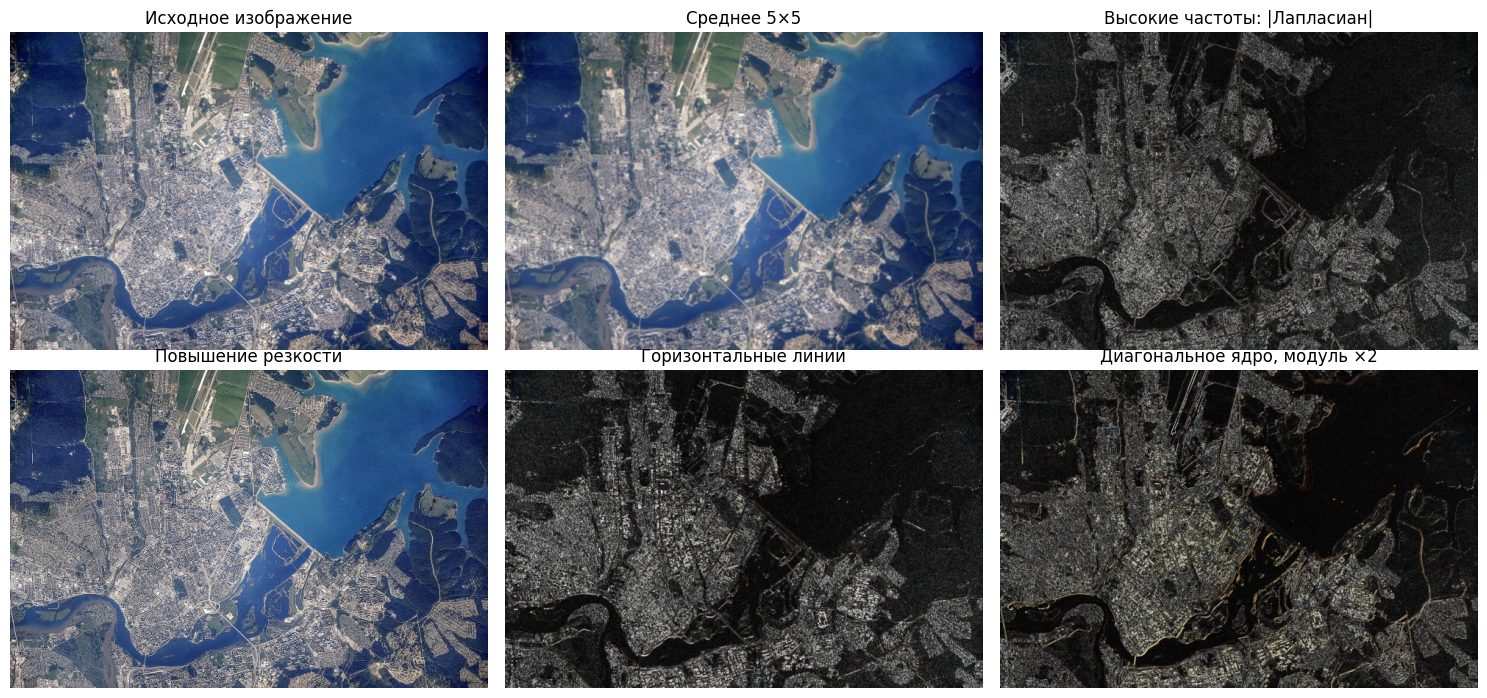

In [6]:
image = read_image(TEACHER / '2.jpg')
panels = [('Исходное изображение', image)]
for key, (title, kernel, mode, gain) in filters.items():
    filtered = apply_filter(image, kernel, mode, gain)
    target = OUT / f'02_{key}.jpg'
    if not cv2.imwrite(str(target), filtered, [cv2.IMWRITE_JPEG_QUALITY, 75]):
        raise OSError(f'Не удалось сохранить {target.name}')
    panels.append((title, filtered))
show_images(panels, '02_comparison.jpg', cols=3)
del panels, filtered, image

После сглаживания мелкие здания стали менее различимыми. Лапласиан выделяет берега и причалы. Фильтр резкости усиливает линейные объекты и мелкие перепады яркости.

### Изображение 3

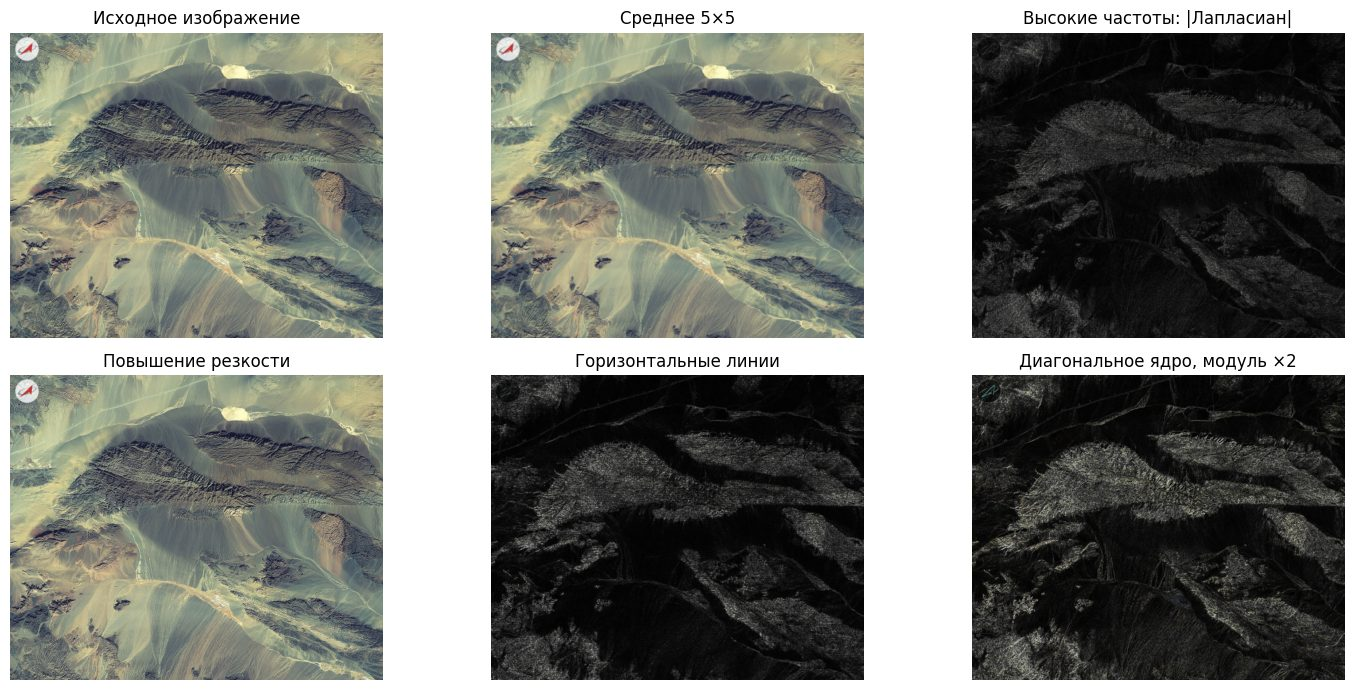

In [7]:
image = read_image(TEACHER / '3.jpg')
panels = [('Исходное изображение', image)]
for key, (title, kernel, mode, gain) in filters.items():
    filtered = apply_filter(image, kernel, mode, gain)
    target = OUT / f'03_{key}.jpg'
    if not cv2.imwrite(str(target), filtered, [cv2.IMWRITE_JPEG_QUALITY, 75]):
        raise OSError(f'Не удалось сохранить {target.name}')
    panels.append((title, filtered))
show_images(panels, '03_comparison.jpg', cols=3)
del panels, filtered, image

Усреднение сгладило небольшие борозды. Высокочастотный фильтр выделяет границы светлых и затенённых склонов. Направленные ядра подчёркивают гребни и ложбины в зависимости от их направления.

### Изображение 4

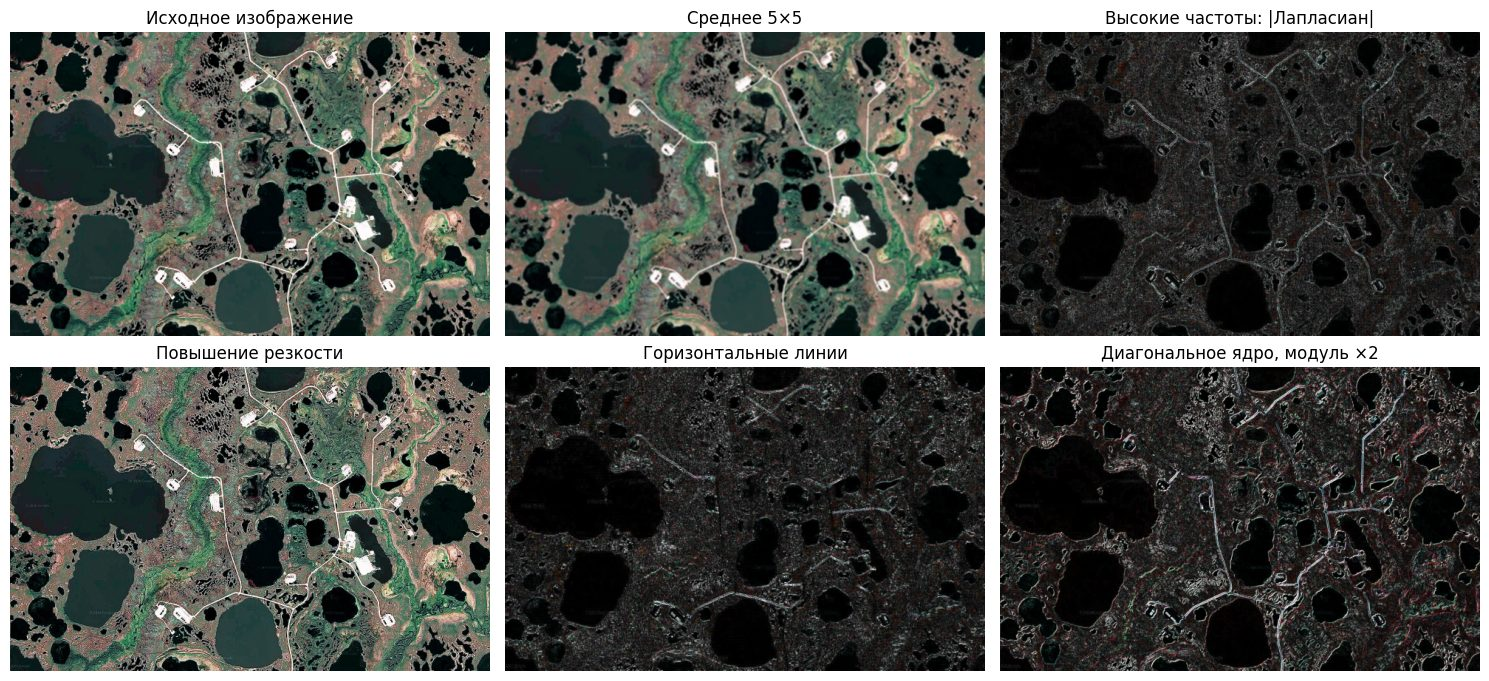

In [8]:
image = read_image(TEACHER / '4.jpg')
panels = [('Исходное изображение', image)]
for key, (title, kernel, mode, gain) in filters.items():
    filtered = apply_filter(image, kernel, mode, gain)
    target = OUT / f'04_{key}.jpg'
    if not cv2.imwrite(str(target), filtered, [cv2.IMWRITE_JPEG_QUALITY, 75]):
        raise OSError(f'Не удалось сохранить {target.name}')
    panels.append((title, filtered))
show_images(panels, '04_comparison.jpg', cols=3)
del panels, filtered, image

При сглаживании берега озёр стали мягче, мелкие строения менее заметны. На Лапласиане лучше видны контуры озёр и дороги. Резкость подчёркивает их границы.

### Изображение 5

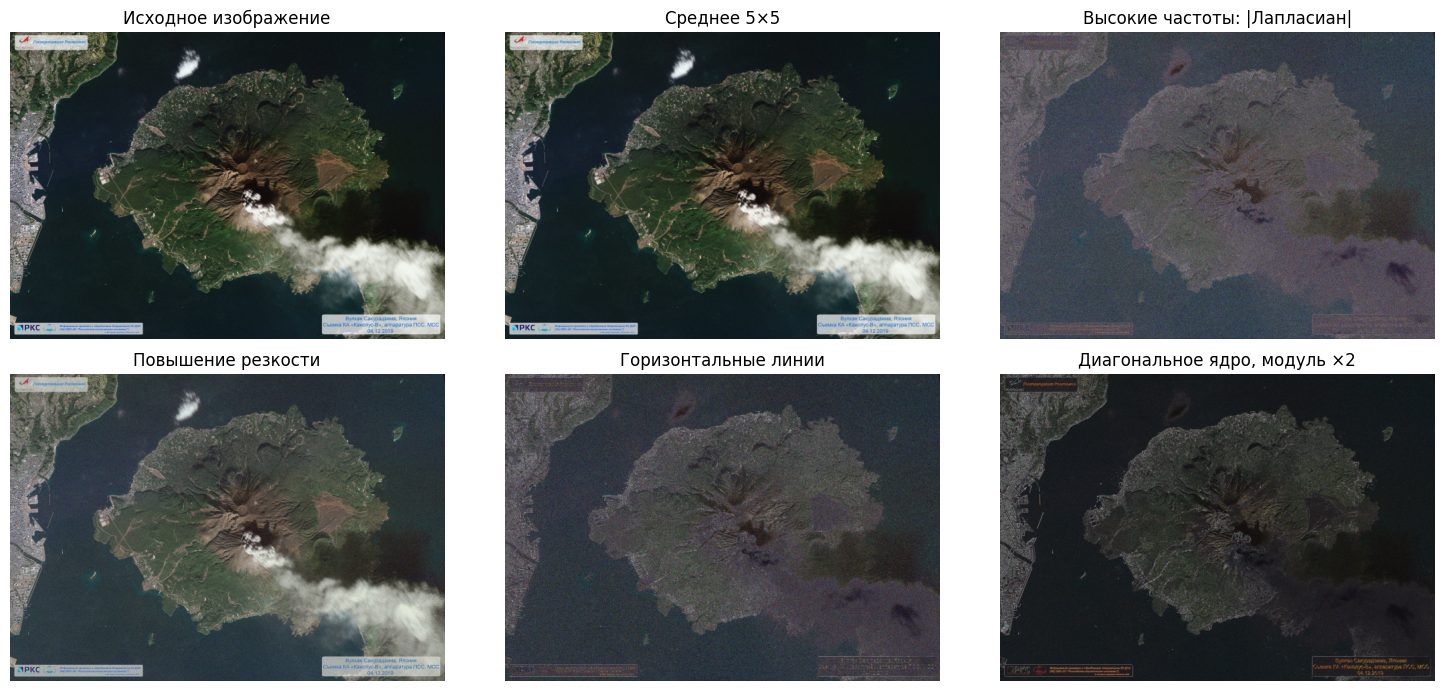

In [9]:
image = read_image(TEACHER / '5.JPG')
panels = [('Исходное изображение', image)]
for key, (title, kernel, mode, gain) in filters.items():
    filtered = apply_filter(image, kernel, mode, gain)
    target = OUT / f'05_{key}.jpg'
    if not cv2.imwrite(str(target), filtered, [cv2.IMWRITE_JPEG_QUALITY, 75]):
        raise OSError(f'Не удалось сохранить {target.name}')
    panels.append((title, filtered))
show_images(panels, '05_comparison.jpg', cols=3)
del panels, filtered, image

Усреднение уменьшило мелкую фактуру склонов и облаков. Лапласиан выделяет берег, края облаков и резкие переходы рельефа. Повышение резкости усиливает гребни, но заодно и подписи на снимке.

Низкочастотный фильтр подходит для сглаживания шума и мелкой фактуры, но размывает небольшие объекты. Высокочастотный помогает выделять границы берегов, дорог, зданий и рельефа. Повышение резкости сохраняет исходный снимок и усиливает детали вместе с шумом.

## Задание 3

Определить свои параметры ядра и указать, для каких целей его можно использовать. Привести примеры.

Использовал ядро `diagonal_kernel = [[-2, -1, 0], [-1, 0, 1], [0, 1, 2]] / 4`. Оно выделяет направленные перепады яркости. Его можно использовать, например, для подчёркивания диагональных участков дорог и складок рельефа.

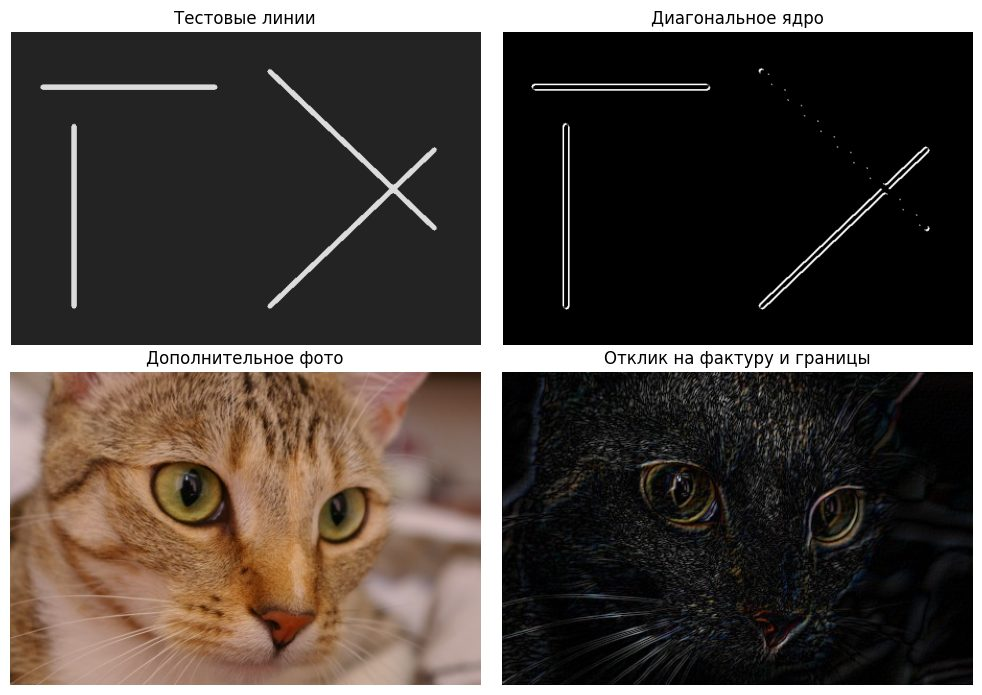

In [10]:
pattern = np.full((400, 600, 3), 35, dtype=np.uint8)
cv2.line(pattern, (40, 70), (260, 70), (220, 220, 220), 5)
cv2.line(pattern, (80, 120), (80, 350), (220, 220, 220), 5)
cv2.line(pattern, (330, 50), (540, 250), (220, 220, 220), 5)
cv2.line(pattern, (330, 350), (540, 150), (220, 220, 220), 5)
save_image('custom_pattern.png', pattern)
pattern_result = apply_filter(pattern, diagonal_kernel, 'abs', 2)
save_image('custom_pattern_diagonal.png', pattern_result)
extra = read_image(LAB / 'images' / 'examples' / 'chelsea.jpg')
extra_result = apply_filter(extra, diagonal_kernel, 'abs', 2)
save_image('custom_photo_diagonal.png', extra_result)
show_images([('Тестовые линии', pattern), ('Диагональное ядро', pattern_result),
             ('Дополнительное фото', extra), ('Отклик на фактуру и границы', extra_result)],
            '06_custom_kernel.jpg')

На тестовых линиях две диагонали дают разный отклик. На фотографии выделились усы и часть границ шерсти. Для другого направления ядро нужно повернуть.